In [19]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time
base_url = "https://books.toscrape.com/catalogue/page-{}.html"
headers = {"User-Agent":("Mozilla/5.0 (Windows NT 10.0; Win64; x64 AppleWebKit/537.36")}
all_books = []
rating_map = {"One": 1 , "Two": 2 , "Three": 3 , "Four": 4 , "Five": 5 }
print("Starting Scrape......")
for page in range(1,11):
    url = base_url.format(page)
    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")
    products = soup.select("article.product_pod")
    for product in products:
        title =  product.select_one("h3 a") ["title"]
        price = product.select_one("p.price_color").get_text(strip= True)
        rating_word =  product.select_one("p.star-rating")["class"][1]
        stock = product.select_one("p.instock.availability").get_text(strip=True)
        all_books.append ({
            "Title": title,
            "Price": price,
            "Rating": rating_map[rating_word],
            "Stock": stock,
        })
    time.sleep(0.2)
df_raw = pd.DataFrame(all_books)
df_raw.to_csv("raw_books.csv", index = False)
print(f"Success. Collected {len(df_raw)} books and saved to raw_books.csv")


Starting Scrape......
Success. Collected 200 books and saved to raw_books.csv


In [20]:
import pandas as pd
df = pd.read_csv("raw_books.csv")
df['Price'] = (df['Price'].astype(str).str.replace(r'[^\d.]', '', regex=True))
df['Price'] = pd.to_numeric(df['Price'], errors = "coerce")
df["Stock"] = df["Stock"].str.strip()
df['Stock_Qty'] = (df['Stock'].str.extract(r'(\d+)').fillna(0).astype(int))
if "Title" in df.columns:
    df["Title"] = df["Title"].astype(str).str.strip()
df = df.dropna(subset=['Price'])
df = df.drop_duplicates()
print("Missing values summary:")
print(df.isnull().sum())
print("-" * 30)
df.to_csv("cleaned_books.csv", index = False)
print("Success. Cleaned data and saved to cleaned_books.csv")
df.head()


Missing values summary:
Title        0
Price        0
Rating       0
Stock        0
Stock_Qty    0
dtype: int64
------------------------------
Success. Cleaned data and saved to cleaned_books.csv


,Title,Price,Rating,Stock,Stock_Qty
0,A Light in the Attic,51.77,3,In stock,0
1,Tipping the Velvet,53.74,1,In stock,0
2,Soumission,50.10,1,In stock,0
3,Sharp Objects,47.82,4,In stock,0
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,0


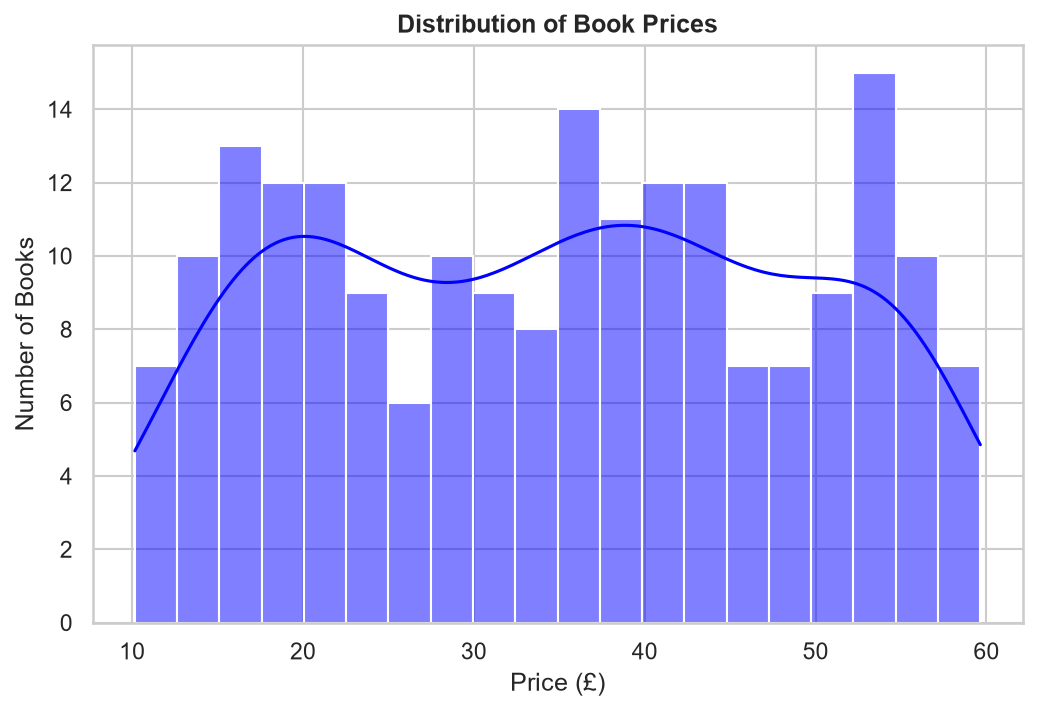

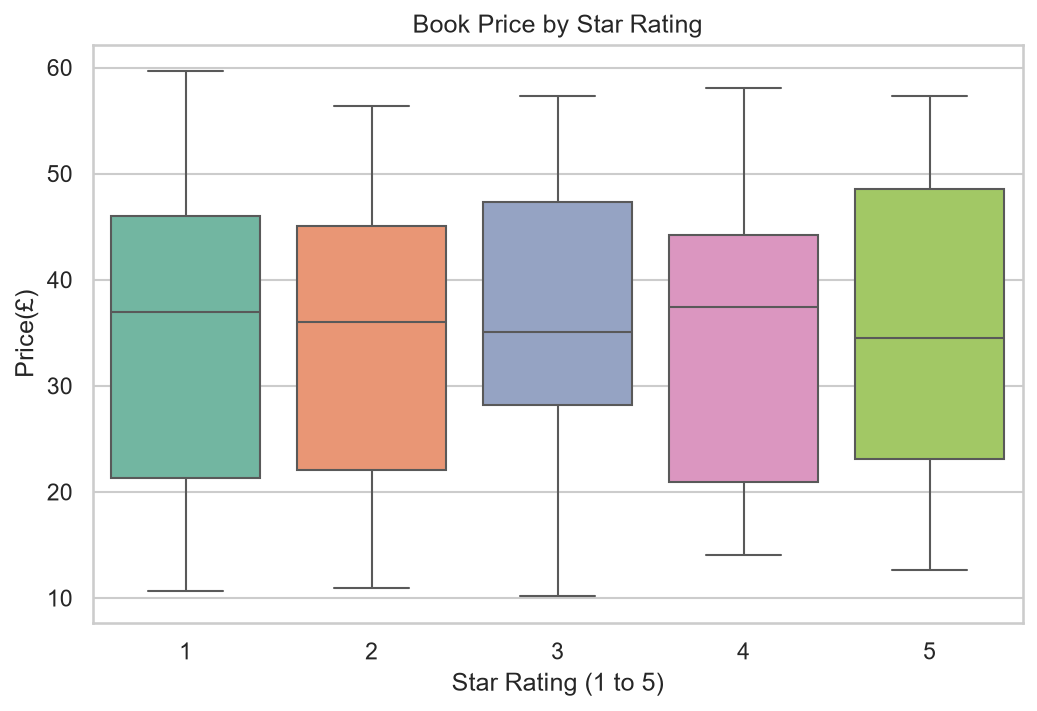

The most expensive book is 'Thomas Jefferson and the Tripoli Pirates: The Forgotten War That Changed American History'at £59.64
The average book price is £34.80


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8,5))
sns.histplot(df["Price"], bins = 20, kde= True, color = "blue")
plt.title("Distribution of Book Prices", fontsize = 12, fontweight = "bold")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.show()
plt.figure(figsize=(8,5))
sns.boxplot(x = "Rating", y="Price", hue = "Rating", data=df, palette = "Set2", legend = False,)
plt.title("Book Price by Star Rating")
plt.xlabel("Star Rating (1 to 5)")
plt.ylabel("Price(£)")
plt.show()
most_expensive_title = df.loc[df['Price'].idxmax()]['Title']
max_price = df["Price"].max()
avg_price = df["Price"].mean()
print(f"The most expensive book is '{most_expensive_title}'at £{max_price:.2f}")
print(f"The average book price is £{avg_price:.2f}")


In [22]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
df = df.dropna(subset= ['Price'])
X = df[['Rating']]
y = df["Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("----MODEL RESULTS---")
print(f"Base Intercept     :£{model.intercept_:.2f}")
print(f"Rating Coefficient (Slope):£{model.coef_[0]:.4f} per star")
print(f"Mean Squared Error (MSE) : {mse:.2f}")
print(f"Root MSE (RMSE) : £{rmse:.2f}")
print(f"R-squared (R^2) Score      :{r2:.4f}")


----MODEL RESULTS---
Base Intercept     :£33.80
Rating Coefficient (Slope):£0.2558 per star
Mean Squared Error (MSE) : 232.73
Root MSE (RMSE) : £15.26
R-squared (R^2) Score      :-0.0085


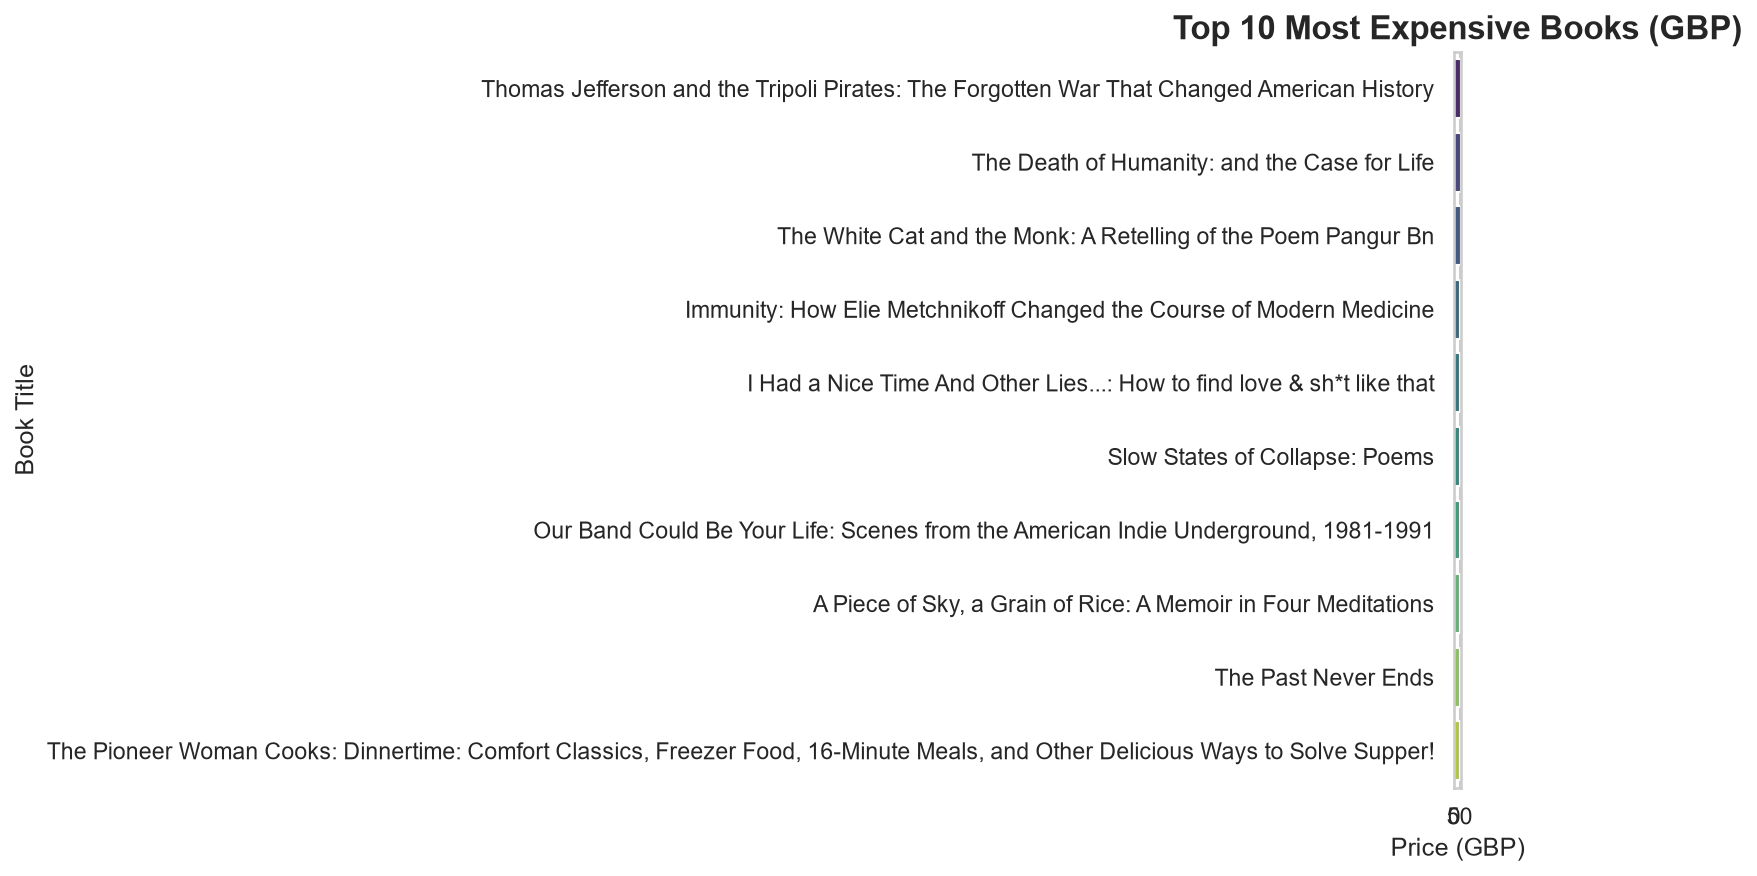

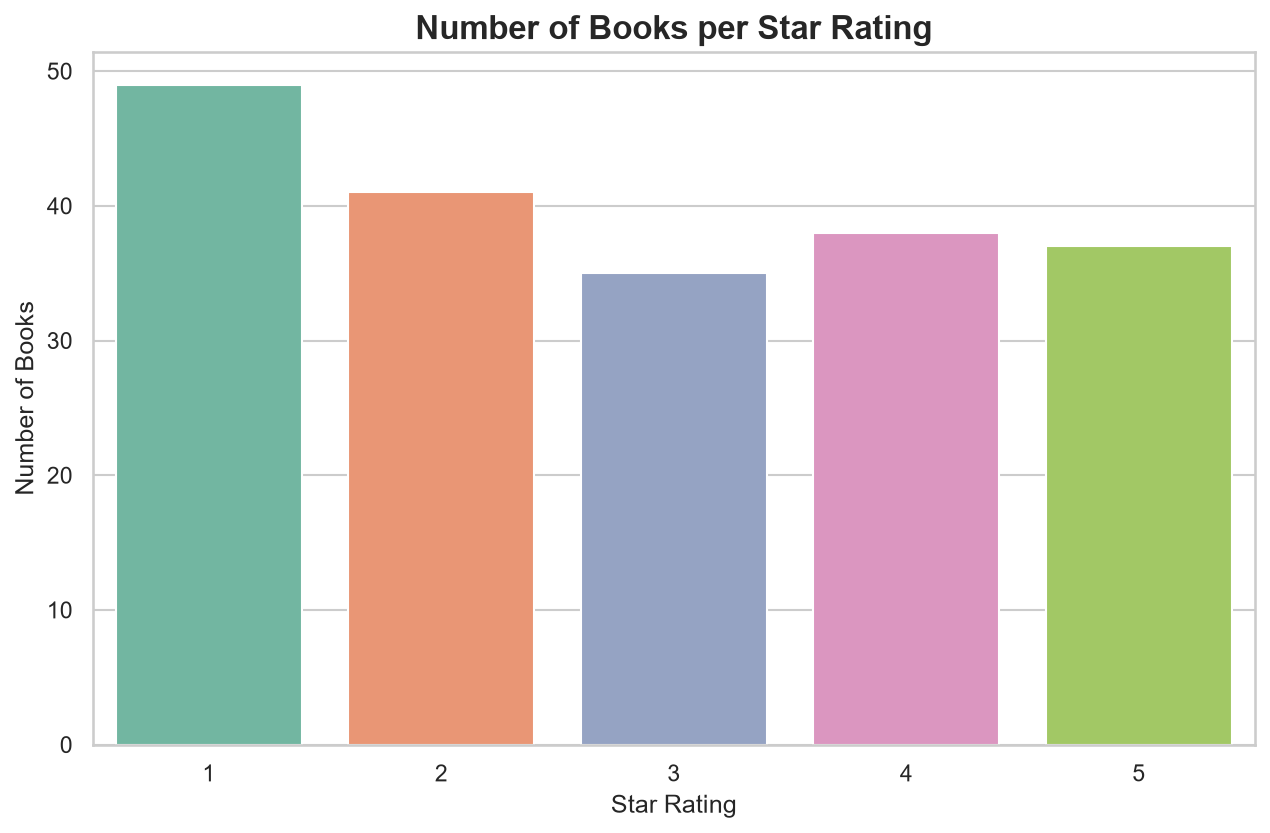

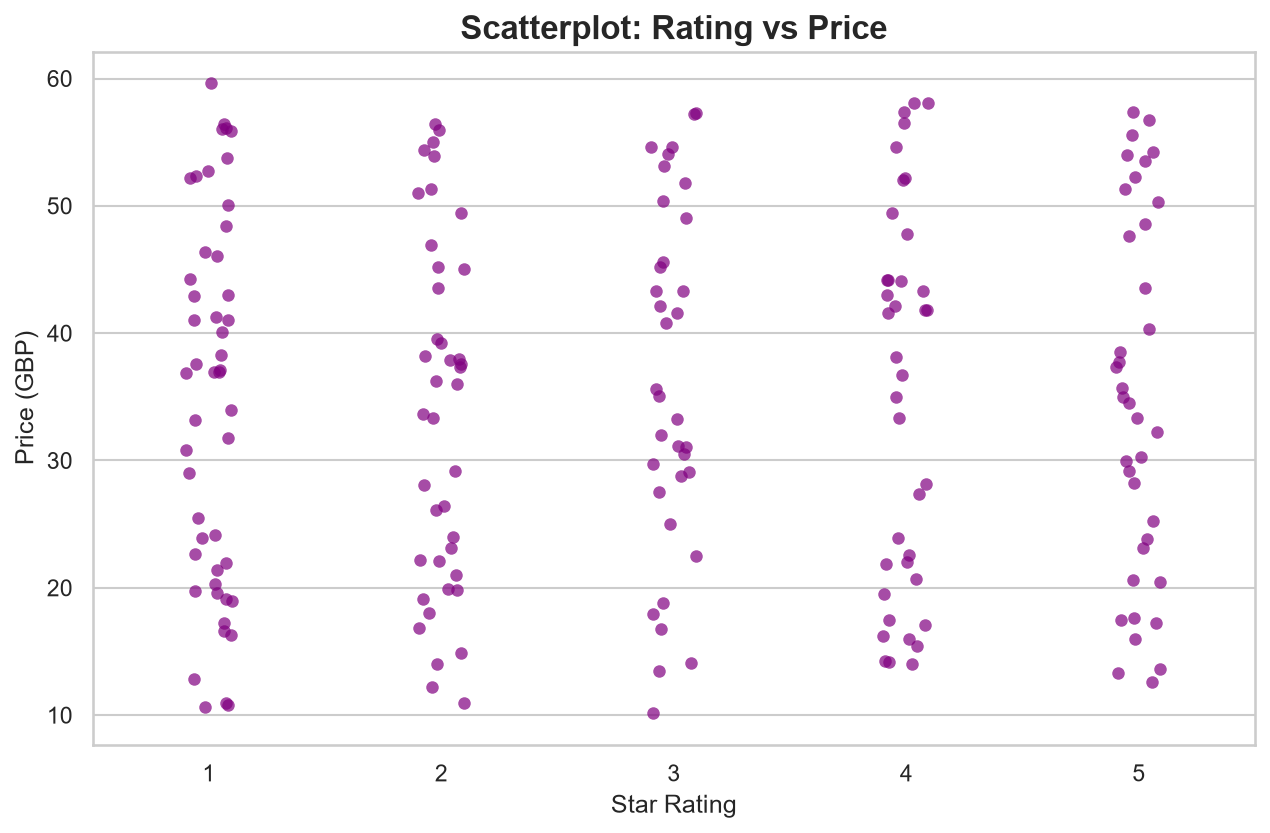

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("cleaned_books.csv")
df['Title'] = df['Title'].str.encode('ascii', 'ignore').str.decode('ascii')
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
top_10 = df.nlargest(10, 'Price')
sns.barplot(x='Price', y='Title', data=top_10, palette='viridis', hue='Title', legend=False)
plt.title('Top 10 Most Expensive Books (GBP)', fontsize = 16, fontweight = 'bold' )
plt.xlabel('Price (GBP)', fontsize=12)
plt.ylabel('Book Title', fontsize=12)
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 6)) # <-- Huge size
sns.countplot(x='Rating', data=df, palette='Set2', hue='Rating', legend=False)
plt.title('Number of Books per Star Rating', fontsize=16, fontweight='bold')
plt.xlabel('Star Rating', fontsize=12)
plt.ylabel('Number of Books', fontsize=12)
plt.show()
plt.figure(figsize=(10, 6))
sns.stripplot(x='Rating', y='Price', data=df, jitter=True, alpha=0.7, color='purple', size=6)
plt.title('Scatterplot: Rating vs Price', fontsize=16, fontweight='bold')
plt.xlabel('Star Rating', fontsize=12)
plt.ylabel('Price (GBP)', fontsize=12)
plt.show()